# PlantMDE organ-wise monocular depth estimation — single spinach example

Reproduction of the demonstration in **"3D plant phenotyping from a single image: learning fine-scale organ morphology with monocular depth estimation"**, *Computers and Electronics in Agriculture* 239:110925 (2025), DOI [10.1016/j.compag.2025.110925](https://doi.org/10.1016/j.compag.2025.110925) (Zhang et al., 2025).

- **Author code**: [`PEESEgroup/PlantMDE`](https://github.com/PEESEgroup/PlantMDE) @ commit `e0592afef771f062b58c4f22df38b2c8c117004d` — this notebook downloads the author's model/metric/visualization modules **verbatim** from that pinned commit and runs the author's demo logic from `MDE_organ_wise.ipynb`.
- **Executed scope**: load the trained **PlantMDE** (ViT-S) checkpoint, predict depth from one bundled spinach RGB image, compute **per-organ Pearson correlation to the ground-truth depth**, and compare against **Depth Anything V2 (ViT-S)**. Render point-cloud projections.
- **Not executed here**: training, the PlantDepth benchmark evaluation, and the paper's dataset-level accuracy claims. One author-provided example is not a verification of published benchmark numbers.
- **Provenance note (English)**: This notebook is an AI-authored Colab adaptation of the author demo `MDE_organ_wise.ipynb`; the scientific modules are the authors' pinned code, not rewritten. It is not author-endorsed.

**日本語**: 論文「3D植物表現型解析を単一画像から」(CEA 239:110925) のデモ再現です。著者リポジトリ PlantMDE のピン留めコミットからコードをそのまま取得し、付属のホウレンソウ画像1枚に対して PlantMDE と Depth Anything V2 の器官ごとの深度相関（Pearson）を比較します。学習やベンチマーク評価は含みません。

## Runtime selection（実行環境の選択）

**Recommended: CPU runtime** (Runtime → Change runtime type → CPU). The demo performs two single-image ViT-S forward passes (518×518); CPU completes in seconds. A GPU (T4) also works — the author's device selection (`cuda` → `mps` → `cpu`) is preserved — but is not required.

Expected wall time: ~5–10 minutes total, dominated by downloads (open3d wheel, two checkpoints ≈ 200 MB+ total, four small PNGs).

**Run all** (`Runtime → Run all`) executes the full demo top-to-bottom. No login, Drive mount, or credentials are needed.

**日本語**: 推奨はCPUランタイムです。ViT-S 1枚推論はCPUで数秒です。GPUでも動作します（著者コードのデバイス選択をそのまま保持）。Run all で先頭から順に実行してください。

### 1. Environment check and dependencies

Colab's preinstalled stack already provides `torch`, `torchvision`, `opencv-python`, `numpy`, `matplotlib`, `pandas` and `gdown`. Only `open3d` is installed explicitly — the authors' `vis.py` imports it at module level (their own `review_pcd` projection used here only draws with matplotlib).

**Expected result**: printed versions of Python/torch/cv2 and a successful `import vis` later; no compilation.

**日本語**: Colabに大部分は同梱済みのため、`open3d` のみ明示的にインストールします（著者の `vis.py` がimportするため）。

In [ ]:
%pip install -q open3d

import sys, platform
import numpy as np
import matplotlib.pyplot as plt
import torch, torchvision, cv2

print('python', platform.python_version())
print('torch', torch.__version__, '| torchvision', torchvision.__version__)
print('cv2', cv2.__version__, '| numpy', np.__version__)
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
print('author device selection ->', DEVICE)

python 3.13.18
torch 2.11.0+cpu | torchvision 0.26.0+cpu
cv2 5.0.0 | numpy 2.1.3
author device selection -> cpu


### 2. Fetch the authors' pinned source code and verify it

All scientific modules are downloaded **verbatim** from `PEESEgroup/PlantMDE` at commit `e0592afef771f062b58c4f22df38b2c8c117004d` and written under `/content/plantmde/`. Each file is verified against the pinned git **blob SHA-1** (`sha1("blob <size>\\0" + bytes)`) and byte size recorded from the GitHub tree, so any modified or truncated download fails here rather than silently changing the method.

**Expected result**: `verified 15 author source files @ <commit>`.

**日本語**: 著者ソース15ファイルをピン留めコミットから取得し、git blob SHA-1とサイズで完全性を検証します。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

COMMIT = 'e0592afef771f062b58c4f22df38b2c8c117004d'
RAW = f'https://raw.githubusercontent.com/PEESEgroup/PlantMDE/{COMMIT}/'
ROOT = Path('/content/plantmde')

CODE_FILES = {
    "dpt/dpt.py": [
        "27d7fb9bcf68e3ca4c55c3551e0b241768ba5ac9",
        7377
    ],
    "dpt/dinov2.py": [
        "83d250818c721c6df3b30d3f4352945527701615",
        15178
    ],
    "dpt/dinov2_layers/__init__.py": [
        "8120f4bc83066cb3f825ce32daa3b437f88486f1",
        382
    ],
    "dpt/dinov2_layers/attention.py": [
        "815a2bf53dbec496f6a184ed7d03bcecb7124262",
        2343
    ],
    "dpt/dinov2_layers/block.py": [
        "25488f57cc0ad3c692f86b62555f6668e2a66db1",
        9332
    ],
    "dpt/dinov2_layers/drop_path.py": [
        "af05625984dd14682cc96a63bf0c97bab1f123b1",
        1160
    ],
    "dpt/dinov2_layers/layer_scale.py": [
        "ca5daa52bd81d3581adeb2198ea5b7dba2a3aea1",
        823
    ],
    "dpt/dinov2_layers/mlp.py": [
        "5e4b315f972f9a9f54aef1e4ef4e81b52976f018",
        1272
    ],
    "dpt/dinov2_layers/patch_embed.py": [
        "574abe41175568d700a389b8b96d1ba554914779",
        2832
    ],
    "dpt/dinov2_layers/swiglu_ffn.py": [
        "b3324b266fb0a50ccf8c3a0ede2ae10ac4dfa03e",
        1859
    ],
    "dpt/util/blocks.py": [
        "382ea183a40264056142afffc201c992a2b01d37",
        3987
    ],
    "dpt/util/transform.py": [
        "b14aacd44ea086b01725a9ca68bb49eadcf37d73",
        6075
    ],
    "util/metric.py": [
        "6aa652d4531d67c30e36ec421bc568371aa16c70",
        8045
    ],
    "util/utils.py": [
        "6cddac0c3cf0ac22e6684ef5831dd5b6044f2d04",
        1553
    ],
    "vis.py": [
        "3569b4a1b10515874f9d87982e0ec2f852f039ac",
        3258
    ]
}

def git_blob_sha(data: bytes) -> str:
    return hashlib.sha1(b'blob %d\x00' % len(data) + data).hexdigest()

for rel, (sha, size) in CODE_FILES.items():
    dest = ROOT / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    data = urllib.request.urlopen(RAW + rel, timeout=120).read()
    assert len(data) == size, f'{rel}: expected {size} bytes, got {len(data)}'
    assert git_blob_sha(data) == sha, f'{rel}: blob SHA mismatch'
    dest.write_bytes(data)
print(f'verified {len(CODE_FILES)} author source files @ {COMMIT}')

verified 15 author source files @ e0592afef771f062b58c4f22df38b2c8c117004d


### 3. Download the authors' spinach example (input data)

The demo uses the four author-provided example files: RGB image, 16-bit ground-truth depth, validity mask, and organ segmentation. These are **sample data**, downloaded to the Colab VM only and verified with the same pinned blob-SHA/size checks.

**Expected result**: `verified 4 example data files @ <commit>`.

**日本語**: デモ用のホウレンソウ画像・GT深度・マスク・器官セグメンテーションをピン留めコミットから取得し検証します。

In [ ]:
EXAMPLE_FILES = {
    "example/rgb/spinach_example.png": [
        "4e2766bb2e8d068674eeb31803ff582848d45e3c",
        933806
    ],
    "example/depth/spinach_example.png": [
        "0c9e8f1caac121565fc5cc1a1a6f0caf8da16fa0",
        18139
    ],
    "example/mask/spinach_example.png": [
        "04dee46854ada340a566ed567859ec0cfef07650",
        2628
    ],
    "example/segmentation/spinach_example.png": [
        "b2f11bba59834fc89939bc96aaa2e9443b36ebba",
        2856
    ]
}

for rel, (sha, size) in EXAMPLE_FILES.items():
    dest = ROOT / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    data = urllib.request.urlopen(RAW + rel, timeout=120).read()
    assert len(data) == size, f'{rel}: expected {size} bytes, got {len(data)}'
    assert git_blob_sha(data) == sha, f'{rel}: blob SHA mismatch'
    dest.write_bytes(data)
print(f'verified {len(EXAMPLE_FILES)} example data files @ {COMMIT}')

verified 4 example data files @ e0592afef771f062b58c4f22df38b2c8c117004d


### 4. Download the two checkpoints

- **PlantMDE (ViT-S)** trained checkpoint — Google Drive file `1DL8ER3Tl2bZzm0CNcrFrrOoiIn_tTnuh`, linked from the README section "PlantMDE model". Fetched with `gdown` to `/content`.
- **Depth Anything V2 (ViT-S)** — public Hugging Face checkpoint `depth_anything_v2_vits.pth` (the authors' designated comparison model).

Both are loaded immediately to confirm integrity: we print only **key names, tensor counts and shapes** — never weight values.

**Expected result**: both files exist, `plantmde.pth` contains a `'model'` state dict with `module.`-prefixed keys; the DA checkpoint is a plain state dict.

**日本語**: PlantMDE（Drive）と Depth Anything V2（HF）のチェックポイントを取得し、キー構成のみ表示して読み込みを確認します（重み値は表示しません）。

In [ ]:
import gdown
from pathlib import Path

CKPT = ROOT / 'checkpoints'
CKPT.mkdir(parents=True, exist_ok=True)
plantmde_vits = CKPT / 'plantmde.pth'
DA_vits = CKPT / 'depth_anything_v2_vits.pth'

if not plantmde_vits.exists():
    gdown.download(id='1DL8ER3Tl2bZzm0CNcrFrrOoiIn_tTnuh', output=str(plantmde_vits), quiet=False)
print('plantmde.pth bytes:', plantmde_vits.stat().st_size)

if not DA_vits.exists():
    urllib.request.urlretrieve(
        'https://huggingface.co/depth-anything/Depth-Anything-V2-Small/resolve/main/depth_anything_v2_vits.pth?download=true',
        str(DA_vits))
print('depth_anything_v2_vits.pth bytes:', DA_vits.stat().st_size)

def load_ckpt(path):
    try:
        return torch.load(path, map_location='cpu')
    except RuntimeError:
        # torch >= 2.6 defaults to weights_only=True; author checkpoints predate that
        return torch.load(path, map_location='cpu', weights_only=False)

pm_ckpt = load_ckpt(plantmde_vits)
assert 'model' in pm_ckpt, f"expected checkpoint dict with 'model' key, got {list(pm_ckpt.keys())}"
sd = pm_ckpt['model']
n_pre = sum(1 for k in sd if k.startswith('module.'))
print(f'plantmde model state dict: {len(sd)} tensors, {n_pre} with module. prefix')
k0 = next(iter(sd))
print('example key:', k0, '->', tuple(sd[k0].shape))

da_ckpt = load_ckpt(DA_vits)
assert isinstance(da_ckpt, dict), type(da_ckpt)
print('DA v2 state dict:', len(da_ckpt), 'tensors')
k0 = next(iter(da_ckpt))
print('example key:', k0, '->', tuple(da_ckpt[k0].shape))

Downloading...
From (original): https://drive.google.com/uc?id=1DL8ER3Tl2bZzm0CNcrFrrOoiIn_tTnuh
From (redirected): https://drive.google.com/uc?id=1DL8ER3Tl2bZzm0CNcrFrrOoiIn_tTnuh&confirm=t&uuid=8cfde078-c623-4c3e-8e7b-0d3ef1d6cf7f
To: /content/plantmde/checkpoints/plantmde.pth


  0%|          | 0.00/297M [00:00<?, ?B/s]

  2%|▏         | 6.82M/297M [00:00<00:04, 61.1MB/s]

  4%|▍         | 13.1M/297M [00:00<00:12, 22.7MB/s]

 14%|█▎        | 40.4M/297M [00:00<00:03, 64.6MB/s]

...

 92%|█████████▏| 274M/297M [00:03<00:00, 87.6MB/s]

100%|██████████| 297M/297M [00:03<00:00, 87.1MB/s]

plantmde.pth bytes: 297117671


depth_anything_v2_vits.pth bytes: 99218434


plantmde model state dict: 239 tensors, 239 with module. prefix
example key: module.pretrained.cls_token -> (1, 1, 384)
DA v2 state dict: 239 tensors
example key: pretrained.cls_token -> (1, 1, 384)


### 5. Import the authors' modules and set the demo constants

Imports mirror the authors' demo cell 0: `DPTModel` from their `dpt/` package, the evaluation helpers `eval_rel_depth_segmentwise` / `align_to_range` and sample utilities `get_samples` / `filer_sample_noise` from `util/`, and `vis` for point-cloud projections. Constants (`vits` config, checkpoint paths, example path) are the authors' values, with paths pointing at the pinned downloads.

One guarded adaptation: the authors call `torch.cuda.set_device(0)` unconditionally, which raises on CPU-only runtimes — it is kept but guarded. The DEVICE expression and the `image2tensor` preprocessing (including the authors' second `BGR2RGB` conversion, preserved verbatim) are unchanged.

**Expected result**: imports succeed and `encoder='vits'` is selected.

**日本語**: 著者デモと同じimport・定数を使用します。CPUでも動くよう `torch.cuda.set_device(0)` をガードした以外は著者コードのままです。

In [ ]:
import sys
import torch.nn.functional as F
from collections import OrderedDict
import cv2

sys.path.insert(0, str(ROOT))

from dpt.dpt import DPTModel
from util.metric import eval_rel_depth, align_by_lstsq, eval_rel_depth_segmentwise, align_to_range
from util.utils import filer_sample_noise, get_samples
import vis  # authors' visualization module (imports open3d; projections here use matplotlib)

if torch.cuda.is_available():
    torch.cuda.set_device(0)  # authors' cell 0, guarded for CPU runtimes
DEVICE = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'

model_configs = {
    'vits': {'encoder': 'vits', 'features': 64, 'out_channels': [48, 96, 192, 384]},
    'vitb': {'encoder': 'vitb', 'features': 128, 'out_channels': [96, 192, 384, 768]},
    'vitl': {'encoder': 'vitl', 'features': 256, 'out_channels': [256, 512, 1024, 1024]},
    'vitg': {'encoder': 'vitg', 'features': 384, 'out_channels': [1536, 1536, 1536, 1536]},
}
encoder = 'vits'
plantmde_vits = str(CKPT / 'plantmde.pth')
DA_vits = str(CKPT / 'depth_anything_v2_vits.pth')
img_path = str(ROOT / 'example' / 'rgb' / 'spinach_example.png')
print('DEVICE =', DEVICE, '| encoder =', encoder)

DEVICE = cpu | encoder = vits


### 6. Per-organ annotation helper (authors' cell 1)

`show_anns` is the authors' visualization helper: for every organ segment (≥500 valid pixels, skipping background id 0) it overlays the segment-wise Pearson coefficient on the predicted depth and outlines each organ with `cv2.findContours`.

**Expected result**: function definition only (no output).

**日本語**: 著者の `show_anns`（器官ごとのPearson注釈と輪郭描画）をそのまま定義します。

In [ ]:
def show_anns(segwise_metric, segmentation, valid_mask, ax):
    metric_list = []
    img = np.ones((segmentation.shape[0], segmentation.shape[1], 4))
    img[:, :, 3] = 0

    for s in segwise_metric:
        smask = segmentation == s['segment_id']
        smask = smask & valid_mask
        if s['segment_id'] == 0 or np.sum(smask) < 500:
            continue
        y, x = np.where(smask)
        metric = s['seg_pearson']
        metric_list.append(metric)
        ax.set_title(f'Segment-wise Metric {np.mean(metric_list):.3f}')

        if len(y) > 0 and len(x) > 0:
            ax.text(np.mean(x), np.mean(y), f'{metric:.2f}', color='black', ha='center', va='center', fontsize=8, bbox=dict(facecolor='black', alpha=0.2))

        contours, _ = cv2.findContours(smask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        for contour in contours:
            cv2.drawContours(img, [contour], -1, (0.0, 0.0, 1.0, 0.6), 1)

    ax.imshow(img)

### 7. Input preview — RGB image and ground-truth depth (authors' cells 3–4)

`get_samples` reads the RGB image, the 16-bit depth PNG (converted to `depth/256`), the organ segmentation and the validity mask (`depth > 0`); the authors' noise filter `filer_sample_noise(depth, mask, 0.016, 0.9996)` trims extreme depth percentiles. The left panel shows the original input; the right panel shows the **ground-truth depth** (reference annotation) with invalid pixels masked.

**Expected result**: spinach rosette image + smooth GT depth map of the same plant.

**日本語**: 入力RGBとGT深度（depth/256、著者のノイズフィルタ適用後）を表示します。

image: (606, 1044, 3) uint8 | depth: (606, 1044) float32
segmentation ids: [0 1 2 3 4 5 6 7]


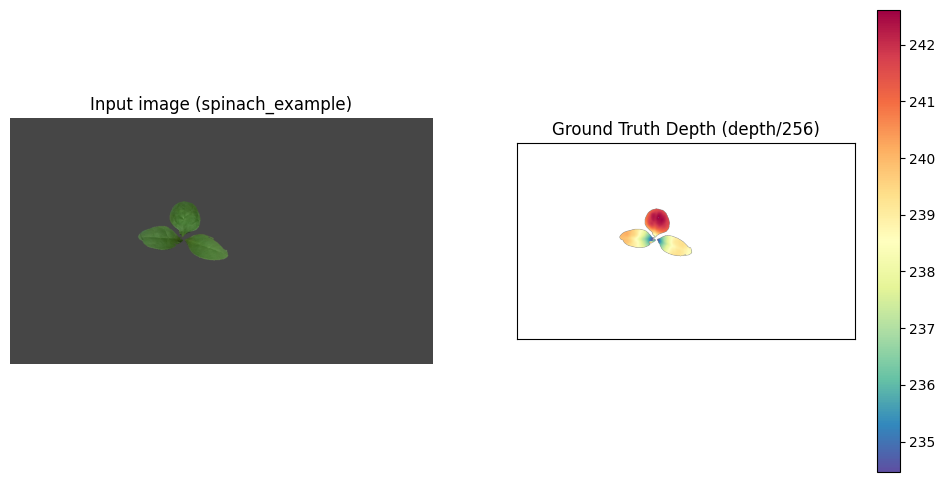

In [ ]:
sample = get_samples(img_path)
ori_image = sample['image']
depth = sample['depth'] / 256
mask = sample['mask']
rgb_mask = depth > 0
segmentation = sample['segmentation']
image = ori_image.copy()
image[rgb_mask == 0] = [70, 70, 70]

print('image:', ori_image.shape, ori_image.dtype, '| depth:', depth.shape, depth.dtype)
print('segmentation ids:', np.unique(segmentation))

mask = filer_sample_noise(depth, mask, 0.016, 0.9996)
depth[mask == 0] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(image)
axes[0].axis('off')
axes[0].set_title('Input image (spinach_example)')
im = axes[1].imshow(depth, cmap='Spectral_r')
axes[1].set_xticks([]); axes[1].set_yticks([])
axes[1].set_title('Ground Truth Depth (depth/256)')
fig.colorbar(im, ax=axes[1])
plt.show()

### 8. PlantMDE inference and organ-wise Pearson metric (authors' cell 6)

The trained checkpoint's `model` state dict (keys stripped of the `module.` prefix, as the authors do) is loaded into the authors' `DPTModel(vits)`. One forward pass predicts relative depth; it is bilinearly resized to the GT resolution. After the authors' validity filtering, `eval_rel_depth_segmentwise` normalizes prediction and GT **per organ segment** and computes the Pearson correlation of each organ independently.

**Expected result**: side-by-side GT depth vs PlantMDE prediction with per-organ Pearson values annotated (mean shown in the panel title).

**日本語**: PlantMDEで推論し、器官ごとに正規化したPearson相関を予測深度上に注釈します。

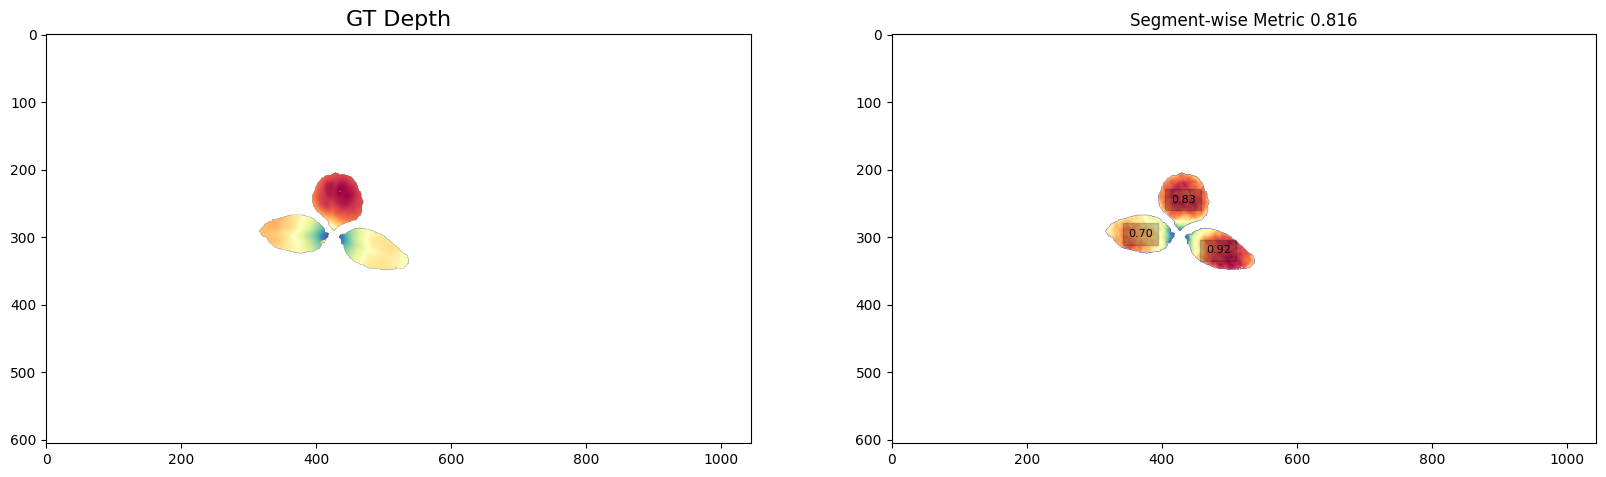

In [ ]:
state_dict = torch.load(plantmde_vits, map_location='cpu')['model']
new_state_dict = OrderedDict()
for k, v in state_dict.items():
    name = k[7:]
    new_state_dict[name] = v
model = DPTModel(**{**model_configs[encoder]})
model.load_state_dict(new_state_dict)
model = model.to(DEVICE).eval()

with torch.no_grad():
    pred_disp = model(model.image2tensor(image)[0])
pred_disp = F.interpolate(pred_disp[:, None], (depth.shape[0], depth.shape[1]), mode='bilinear', align_corners=True)[0, 0].cpu().detach().numpy()

valid_mask_filter = filer_sample_noise(pred_disp, mask, 0.05, 1)
valid_mask_filter_base = valid_mask_filter
depth_mask = np.copy(depth)
depth_mask[valid_mask_filter == 0] = np.nan
pred_disp[valid_mask_filter == 0] = np.nan

segwise_metric = eval_rel_depth_segmentwise(pred_disp, depth_mask, valid_mask_filter, segmentation, [0.00, 1], retrun_segmentwise_metrics=True)
plantmde_segwise = segwise_metric

fig, ax = plt.subplots(1, 2, figsize=(20, 10))
ax[0].imshow(depth_mask, cmap='Spectral_r')
ax[0].set_title('GT Depth', fontsize=16)
ax[1].imshow(pred_disp, cmap='Spectral_r')
show_anns(segwise_metric, segmentation, valid_mask_filter, ax[1])
plt.show()

### 9. PlantMDE depth → point-cloud projections (authors' cell 8)

Following the authors, the prediction is range-aligned to the GT depth (`align_to_range`) and back-projected with the demo's pinhole parameters (f=1387.8287 px). `vis.review_pcd` draws three orthographic scatter views (two side views, top view) with RGB colors — a quick substitute for their interactive open3d viewer.

**Expected result**: three scatter panels of the reconstructed plant point cloud.

**日本語**: 予測深度をGTレンジに整合させ、pinhole逆投影で点群を3方向から描画します。

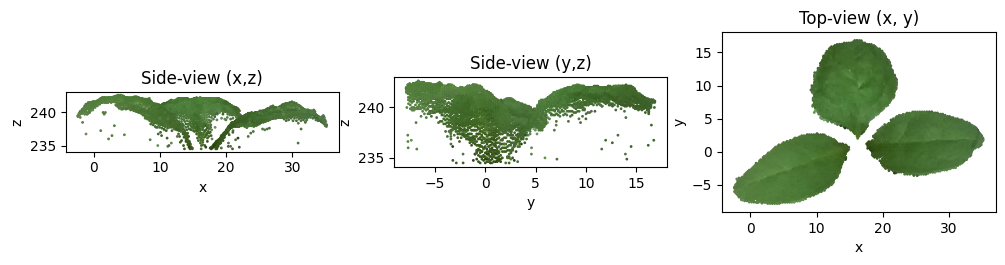

In [ ]:
masked_img = np.copy(ori_image)
masked_img[valid_mask_filter == 0] = [0, 0, 0]
nor_depth = align_to_range(pred_disp, depth_mask, valid_mask_filter)
nor_depth[valid_mask_filter == 0] = np.nan
points, colors = vis.depth_to_cloud_point(masked_img, nor_depth, 1387.8287, 1387.8287)
point_color = np.hstack((points, colors))

vis.review_pcd(points, colors, 2)  # quick matplotlib review; open3d gives a better interactive view

### 10. Depth Anything V2 comparison and organ-wise metric (authors' cell 10)

The public Depth Anything V2 (ViT-S) checkpoint is loaded into the same `DPTModel` architecture (the authors' design — the two models share the head). The identical metric pipeline runs on its prediction; the validity mask combines both models' noise filters, as in the authors' cell (`valid_mask & valid_mask_filter_base`).

**Expected result**: DA V2 prediction with per-organ Pearson annotations, directly comparable to step 8.

**日本語**: 比較用の Depth Anything V2 (ViT-S) で同じ評価を行い、PlantMDEと比較します。

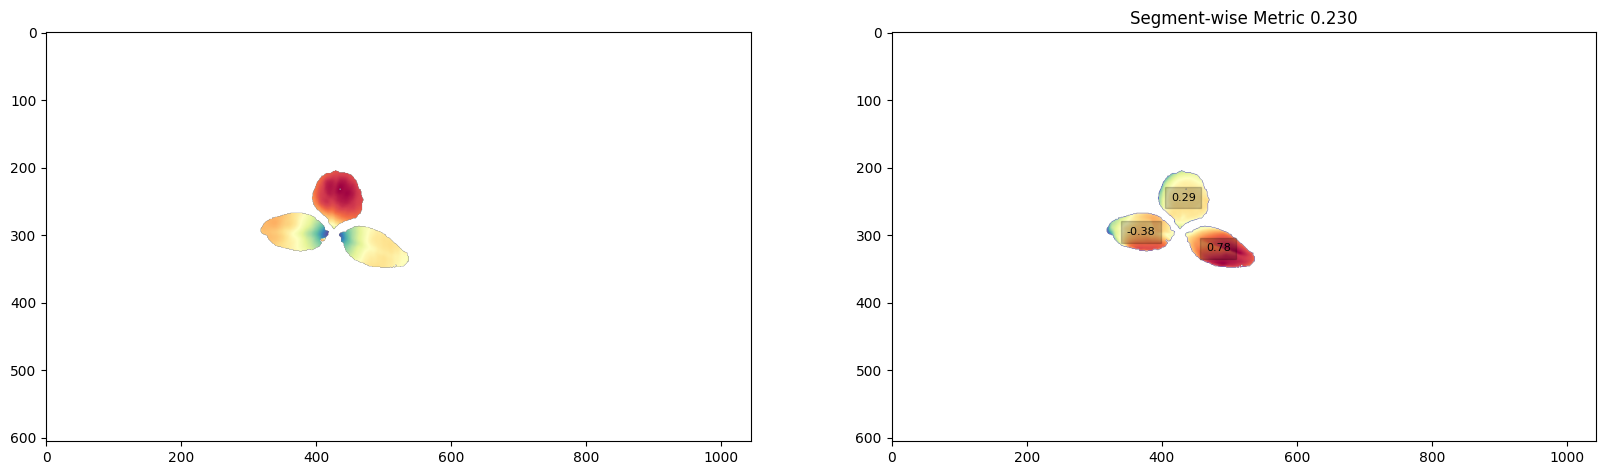

In [ ]:
new_state_dict = torch.load(DA_vits, map_location='cpu')
model2 = DPTModel(**{**model_configs[encoder]})
model2.load_state_dict(new_state_dict)
model2 = model2.to(DEVICE).eval()

with torch.no_grad():
    pred_disp = model2(model2.image2tensor(ori_image)[0])
pred_disp = F.interpolate(pred_disp[:, None], (depth.shape[0], depth.shape[1]), mode='bilinear', align_corners=True)[0, 0].cpu().detach().numpy()

valid_mask_filter = filer_sample_noise(pred_disp, mask, 0.01, 1)
valid_mask_filter = valid_mask_filter & valid_mask_filter_base
depth_mask = np.copy(depth)
depth_mask[valid_mask_filter == 0] = np.nan
pred_disp[valid_mask_filter == 0] = np.nan

segwise_metric = eval_rel_depth_segmentwise(pred_disp, depth_mask, valid_mask_filter, segmentation, [0.01, 1], retrun_segmentwise_metrics=True)
da_segwise = segwise_metric

fig, ax = plt.subplots(1, 2, figsize=(20, 20))
ax[0].imshow(depth_mask, cmap='Spectral_r')
ax[1].imshow(pred_disp, cmap='Spectral_r')
show_anns(segwise_metric, segmentation, valid_mask_filter, ax[1])
plt.show()

### 11. Depth Anything V2 point-cloud projections (authors' cell 11)

The same range-alignment and back-projection applied to the DA V2 prediction, for visual comparison with step 9.

**Expected result**: three scatter panels for the DA V2 reconstruction.

**日本語**: DA V2の予測に対しても同じ点群描画を行います。

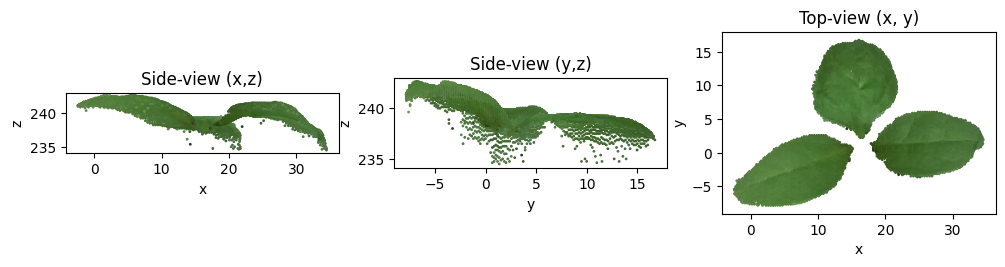

In [ ]:
masked_img = np.copy(ori_image)
masked_img[valid_mask_filter == 0] = [0, 0, 0]
nor_depth = align_to_range(pred_disp, depth_mask, valid_mask_filter)
nor_depth[valid_mask_filter == 0] = np.nan
points, colors = vis.depth_to_cloud_point(masked_img, nor_depth, 1387.8287, 1387.8287)
point_color = np.hstack((points, colors))

vis.review_pcd(points, colors, 2)

### 12. Per-organ results table

The organ-wise Pearson coefficients from steps 8 and 10 are tabulated side by side (segments with ≥500 valid pixels, background id 0 excluded — the same rule as `show_anns`), plus the per-model mean. This is the demo's headline comparison: higher per-organ Pearson means the predicted depth follows the fine-scale geometry of each organ more faithfully. This single-example table does **not** reproduce the paper's benchmark statistics.

A CSV is also written under `/content/plantmde/`.

**Expected result**: a small table listing each organ segment's Pearson for PlantMDE vs Depth Anything V2 and their means.

**日本語**: 器官ごとのPearsonを2モデルで並べた表と平均を表示します（単一例であり論文のベンチマーク値ではありません）。

In [ ]:
import pandas as pd

def organ_table(segwise, min_px=500):
    rows = []
    for s in segwise:
        sid = s['segment_id']
        if sid == 0:
            continue
        px = int(np.sum((segmentation == sid) & valid_mask_filter_base))
        if px < min_px:
            continue
        rows.append({'segment_id': sid, 'pixels': px, 'pearson': s['seg_pearson']})
    return pd.DataFrame(rows).set_index('segment_id')

tb_pm = organ_table(plantmde_segwise)
tb_da = organ_table(da_segwise)
table = tb_pm[['pixels', 'pearson']].join(tb_da[['pearson']], lsuffix='_PlantMDE', rsuffix='_DAv2')
table.columns = ['pixels', 'pearson_PlantMDE', 'pearson_DepthAnythingV2']
display(table)
print(table.mean(numeric_only=True))
table.to_csv(ROOT / 'organ_pearson_spinach_example.csv')
print('saved', ROOT / 'organ_pearson_spinach_example.csv')

,pixels,pearson_PlantMDE,pearson_DepthAnythingV2
segment_id,,,
3,4488,0.834586,0.291433
5,4188,0.916890,0.782096
7,4134,0.695627,-0.383273


pixels                     4270.000000
pearson_PlantMDE              0.815701
pearson_DepthAnythingV2       0.230085
dtype: float64
saved /content/plantmde/organ_pearson_spinach_example.csv


## Interpretation and limitations（解釈と限界）

- This notebook executes the authors' own demo path on their own bundled example: PlantMDE and Depth Anything V2 (ViT-S) predict depth for one spinach image, scored by the authors' segment-wise Pearson metric. PlantMDE's organ-wise Pearson is expected to exceed DA V2's on this example, consistent with the paper's claim that dataset-mixed training improves fine-scale organ geometry — but **one example is anecdotal evidence, not a reproduction of the paper's benchmark results**.
- Metric details (per-organ normalization, ≥100 px segments, outlier quantiles) come verbatim from the authors' `util/metric.py`; the exact organ-wise metric definition in the paywalled paper was not consulted — the pinned code is the primary evidence for the executed computation.
- Limitations: relative depth only (scale aligned for display/back-projection); the focal length 1387.8287 and the checkpoint↔journal-version correspondence rest on the authors' README/demo; the repository ships no LICENSE file (the PlantDepth dataset is stated MIT); Drive downloads can occasionally hit quota errors — rerun the download cell if so.

**日本語**: 本ノートブックは著者自身のデモを著者の例画像で実行したものです。単一例の結果であり、論文のベンチマーク統計の再現ではありません。相対深度であり、スケールは表示・逆投影のために整合させています。

## References

- Zhang et al., "3D plant phenotyping from a single image: learning fine-scale organ morphology with monocular depth estimation", *Computers and Electronics in Agriculture* 239:110925 (2025). DOI: 10.1016/j.compag.2025.110925
- Code: https://github.com/PEESEgroup/PlantMDE @ `e0592afef771f062b58c4f22df38b2c8c117004d` (incl. `MDE_organ_wise.ipynb`, `dpt/`, `util/metric.py`, `util/utils.py`, `vis.py`)
- Checkpoints: PlantMDE (Google Drive, README link) · Depth-Anything-V2-Small (Hugging Face, `depth_anything_v2_vits.pth`)
- Dataset (not used in this demo): PlantDepth, Zenodo record 23017847 / Drive, MIT license per README.